# 05 — Word2Vec Semantic Matching

## Project overview
Word2Vec learns word representations from the project text. Averaged document vectors and cosine similarity provide a semantic-matching signal beyond exact word overlap.

**Outputs:** `word2vec_results.csv` and `word2vec_model.model`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity

from project_utils import tokenize_text, document_vector

In [2]:
df = pd.read_csv(r"D:\Instant AI\AI\Graduation Project\My Project\Data\processed_data.csv")


In [3]:
df.head()

,career_objective,skills,educational_institution_name,degree_names,passing_years,educational_results,result_types,major_field_of_studies,professional_company_names,start_dates,...,expiry_dates,job_position_name,educationaL_requirements,experiencere_requirement,skills_required,matched_score,candidate_text,job_text,candidate_text_length,job_text_length
0,big data analytics working and database wareho...,"['big data', 'hadoop', 'hive', 'python', 'mapr...",['the amity school of engineering & technology...,['b.tech'],['2019'],['n/a'],[none],['electronics'],['coca-cola'],['nov 2019'],...,NaN,senior software engineer,b.sc in computer science & engineering from a ...,at least 1 year,NaN,0.850000,big data analytics working and database wareho...,senior software engineer b.sc in computer scie...,653,257
1,fresher looking to join as a data analyst and ...,"['data analysis', 'data analytics', 'business ...","['delhi university - hansraj college', 'delhi ...","['b.sc (maths)', 'm.sc (science) (statistics)']","['2015', '2018']","['n/a', 'n/a']","['n/a', 'n/a']","['mathematics', 'statistics']",['bib consultancy'],['sep 2019'],...,NaN,machine learning (ml) engineer,m.sc in computer science & engineering or in a...,at least 5 year(s),NaN,0.750000,fresher looking to join as a data analyst and ...,machine learning (ml) engineer m.sc in compute...,554,534
2,NaN,"['software development', 'machine learning', '...","['birla institute of technology (bit), ranchi']",['b.tech'],['2018'],['n/a'],['n/a'],['electronics/telecommunication'],['axis bank limited'],['june 2018'],...,NaN,"executive/ senior executive- trade marketing, ...",master of business administration (mba),at least 3 years,brand promotion campaign management field supe...,0.416667,"['software development', 'machine learning', '...","executive/ senior executive- trade marketing, ...",446,365
3,to obtain a position in a fast-paced business ...,"['accounts payables', 'accounts receivables', ...","['martinez adult education, business training ...",['computer applications specialist certificate...,['2008'],[none],[none],['computer applications'],"['company name ï¼ city , state', 'company name...","['january 2011', 'january 2008', 'january 2006...",...,NaN,business development executive,bachelor/honors,1 to 3 years,fast typing skill ieltsinternet browsing & onl...,0.760000,to obtain a position in a fast-paced business ...,business development executive bachelor/honors...,1844,209
4,professional accountant with an outstanding wo...,"['analytical reasoning', 'compliance testing k...",['kent state university'],['bachelor of business administration'],[none],['3.84'],[none],['accounting'],"['company name', 'company name', 'company name...","['january 2016', 'january 2016', 'january 2012...",...,"['february 15, 2021']",senior ios engineer,bachelor of science (bsc) in computer science,at least 4 years,ios ios app developer ios application developm...,0.650000,professional accountant with an outstanding wo...,senior ios engineer bachelor of science (bsc) ...,1783,485


## 1. Tokenize candidate and job text
Lowercase, remove punctuation, and split text into tokens.

In [4]:
sample_text="Python Developer, Machine Learning and AI"

tokenize_text(sample_text)

['python', 'developer', 'machine', 'learning', 'and', 'ai']

In [5]:
candidate_tokens=df["candidate_text"].apply(tokenize_text)
candidate_tokens.head()

0    [big, data, analytics, working, and, database,...
1    [fresher, looking, to, join, as, a, data, anal...
2    [software, development, machine, learning, dee...
3    [to, obtain, a, position, in, a, fast, paced, ...
4    [professional, accountant, with, an, outstandi...
Name: candidate_text, dtype: object

In [6]:
job_tokens=df["job_text"].apply(tokenize_text)
job_tokens.head()

0    [senior, software, engineer, b, sc, in, comput...
1    [machine, learning, ml, engineer, m, sc, in, c...
2    [executive, senior, executive, trade, marketin...
3    [business, development, executive, bachelor, h...
4    [senior, ios, engineer, bachelor, of, science,...
Name: job_text, dtype: object

## 2. Prepare Word2Vec training sentences
Candidate and job token lists form the training corpus.

In [7]:
sentences=list(candidate_tokens)+list(job_tokens)
len(sentences)

19088

In [8]:
sentences[:3]

[['big',
  'data',
  'analytics',
  'working',
  'and',
  'database',
  'warehouse',
  'manager',
  'with',
  'robust',
  'experience',
  'in',
  'handling',
  'all',
  'kinds',
  'of',
  'data',
  'i',
  'have',
  'also',
  'used',
  'multiple',
  'cloud',
  'infrastructure',
  'services',
  'and',
  'am',
  'well',
  'acquainted',
  'with',
  'them',
  'currently',
  'in',
  'search',
  'of',
  'role',
  'that',
  'offers',
  'more',
  'of',
  'development',
  'big',
  'data',
  'hadoop',
  'hive',
  'python',
  'mapreduce',
  'spark',
  'java',
  'machine',
  'learning',
  'cloud',
  'hdfs',
  'yarn',
  'core',
  'java',
  'data',
  'science',
  'c',
  'data',
  'structures',
  'dbms',
  'rdbms',
  'informatica',
  'talend',
  'amazon',
  'redshift',
  'microsoft',
  'azure',
  'the',
  'amity',
  'school',
  'of',
  'engineering',
  'technology',
  'aset',
  'noida',
  'b',
  'tech',
  'electronics',
  'coca',
  'cola',
  'big',
  'data',
  'analyst',
  'big',
  'data'],
 ['fresher

## 3. Train the Word2Vec model
The existing configuration uses 100-dimensional vectors, window 5, `min_count=2`, skip-gram, four workers, and seed 42.

In [9]:
word2vec_model = Word2Vec(
    sentences=sentences, vector_size=100, window=5,
    min_count=2, workers=4, sg=1, epochs=20, seed=42
)

In [10]:
len(word2vec_model.wv)

4958

In [11]:
word2vec_model.wv['python']

array([-7.7593142e-01,  2.5797930e-01, -8.7188020e-02,  2.1271600e-01,
       -8.7430936e-01, -1.0032587e-01, -4.0568072e-02,  8.7271428e-01,
       -1.5668286e-01,  2.8737354e-01, -5.1869869e-01, -3.5249588e-01,
       -1.0692837e-01,  3.4918922e-01,  9.2566140e-02, -1.1789011e+00,
        5.3071296e-03,  2.6966560e-01,  4.1545331e-01,  2.9007110e-01,
       -4.2853358e-01, -2.2067411e-01,  1.4259519e-01,  4.7175577e-01,
        4.2442489e-01,  1.3062638e-01, -4.7823733e-01, -3.7364802e-01,
       -9.4328560e-02, -3.0170670e-01, -4.6913162e-02, -4.8567632e-01,
        8.6329682e-03, -5.2689624e-01, -3.9218363e-01, -1.5195122e-01,
        8.0500735e-04, -6.7775476e-01,  3.1659788e-01, -1.3825098e-01,
       -7.2321391e-01,  4.0569492e-02, -4.8587239e-01, -8.4125203e-01,
        3.8564868e-02, -9.7292602e-02, -1.6694287e-03,  9.5559862e-03,
        7.5127512e-01, -2.3913166e-01, -3.2727313e-01, -3.4264520e-01,
       -4.7860181e-01, -5.7194110e-02,  5.5229223e-01, -2.1247137e-01,
      

In [12]:
word2vec_model.wv.most_similar('python', topn=10)

[('pandas', 0.5381961464881897),
 ('tableau', 0.5187628865242004),
 ('r', 0.48947134613990784),
 ('node', 0.48300233483314514),
 ('numpy', 0.4780648648738861),
 ('js', 0.47439733147621155),
 ('tensorflow', 0.4647533595561981),
 ('django', 0.4626396596431732),
 ('jax', 0.4581643342971802),
 ('japanese', 0.4503655433654785)]

## 4. Build document vectors
Each document is represented by the average of the Word2Vec vectors available for its tokens.

In [13]:
test_vector=document_vector(
    candidate_tokens.iloc[0],
    word2vec_model
)

test_vector.shape

(100,)

In [14]:
candidate_vectors_w2v=np.array([
    document_vector(tokens,word2vec_model)
    for tokens in candidate_tokens
])

candidate_vectors_w2v.shape

(9544, 100)

In [15]:
job_vectors_w2v=np.array([
    document_vector(tokens,word2vec_model)
    for tokens in job_tokens
])

job_vectors_w2v.shape

(9544, 100)

## 5. Calculate semantic similarity
Candidate and job document vectors are normalized and compared using cosine similarity.

In [16]:
candidate_norms = np.linalg.norm(
    candidate_vectors_w2v,
    axis=1,
    keepdims=True
)

job_norms = np.linalg.norm(
    job_vectors_w2v,
    axis=1,
    keepdims=True
)

candidate_vectors_normalized = (
    candidate_vectors_w2v / np.maximum(candidate_norms, 1e-10)
)

job_vectors_normalized = (
    job_vectors_w2v / np.maximum(job_norms, 1e-10)
)

pairwise_similarity_w2v = np.sum(
    candidate_vectors_normalized * job_vectors_normalized,
    axis=1
)

In [17]:
pairwise_similarity_w2v[:10]

array([0.6929816 , 0.8343998 , 0.473196  , 0.6812194 , 0.5495057 ,
       0.71705014, 0.5064165 , 0.57704765, 0.5570091 , 0.57424194],
      dtype=float32)

In [18]:
df["word2vec_similarity"]=pairwise_similarity_w2v

df[
    [
        "candidate_text",
        "job_text",
        "matched_score",
        "word2vec_similarity"
    ]
].head()

,candidate_text,job_text,matched_score,word2vec_similarity
0,big data analytics working and database wareho...,senior software engineer b.sc in computer scie...,0.850000,0.692982
1,fresher looking to join as a data analyst and ...,machine learning (ml) engineer m.sc in compute...,0.750000,0.834400
2,"['software development', 'machine learning', '...","executive/ senior executive- trade marketing, ...",0.416667,0.473196
3,to obtain a position in a fast-paced business ...,business development executive bachelor/honors...,0.760000,0.681219
4,professional accountant with an outstanding wo...,senior ios engineer bachelor of science (bsc) ...,0.650000,0.549506


## 6. Evaluate the semantic signal
Pearson and Spearman correlations, a scatter plot, and examples help interpret the semantic signal.

In [19]:
pearson_corr=df[
    ["matched_score","word2vec_similarity"]
].corr(method="pearson").iloc[0,1]

print("Pearson correlation:",pearson_corr)

Pearson correlation: 0.4029516731350098


In [20]:
spearman_corr=df[
    ["matched_score","word2vec_similarity"]
].corr(method="spearman").iloc[0,1]

print("Spearman correlation:",spearman_corr)

Spearman correlation: 0.43842592517644347


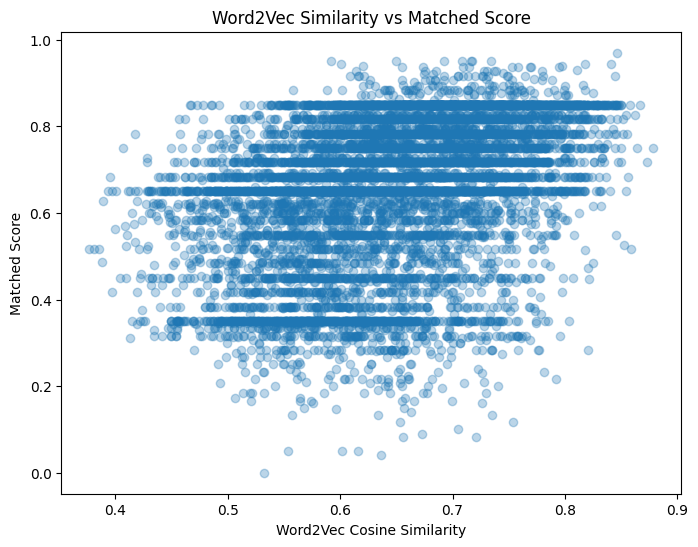

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df['word2vec_similarity'],
    df['matched_score'],
    alpha=0.3
)

plt.xlabel('Word2Vec Cosine Similarity')
plt.ylabel('Matched Score')
plt.title('Word2Vec Similarity vs Matched Score')

plt.show()

In [22]:
df[
    [
        "job_position_name",
        "matched_score",
        "word2vec_similarity"
    ]
].sort_values(
    "word2vec_similarity",ascending=False
).head()

,job_position_name,matched_score,word2vec_similarity
2950,site engineer,0.750000,0.878361
3071,site engineer,0.716667,0.872888
693,site engineer,0.850000,0.867048
8172,hr officer,0.750000,0.863718
3721,site engineer,0.826667,0.862063


In [23]:
df[
    [
        "job_position_name",
        "matched_score",
        "word2vec_similarity"
    ]
].sort_values(
    "word2vec_similarity",ascending=True
).head()

,job_position_name,matched_score,word2vec_similarity
4277,hr officer,0.516667,0.377118
5419,executive - vat,0.516667,0.381443
2084,business development executive,0.516667,0.385965
9006,executive - vat,0.486667,0.388345
2651,executive - vat,0.626667,0.389019


## 7. Save the results and model
Save the similarity results and trained Word2Vec model for the final pipeline.

In [24]:
df.to_csv(
    "D:\Instant AI\AI\Graduation Project\My Project\Data/word2vec_results.csv",
    index=False
)

<>:2: SyntaxWarning: invalid escape sequence '\I'
<>:2: SyntaxWarning: invalid escape sequence '\I'
C:\Users\mazen\AppData\Local\Temp\ipykernel_27196\3349896618.py:2: SyntaxWarning: invalid escape sequence '\I'
  "D:\Instant AI\AI\Graduation Project\My Project\Data/word2vec_results.csv",


In [25]:
word2vec_model.save(
    'D:\Instant AI\AI\Graduation Project\My Project\Models/word2vec_model.model'
)

<>:2: SyntaxWarning: invalid escape sequence '\I'
<>:2: SyntaxWarning: invalid escape sequence '\I'
C:\Users\mazen\AppData\Local\Temp\ipykernel_27196\4012445855.py:2: SyntaxWarning: invalid escape sequence '\I'
  'D:\Instant AI\AI\Graduation Project\My Project\Models/word2vec_model.model'
